In [1]:
import os, sys, glob, io, contextlib, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path, connected_components
from scipy.stats import spearmanr
from sklearn.neighbors import NearestNeighbors
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # e.g. Bischoff2021_Lung-2
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Lung
data_name = re.sub(r'-\d+$', '', name)                  # strip attempt suffix -> Bischoff2021_Lung
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + data_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| input:', 'Data_'+data_name)

dataset: Bischoff2021_Lung-2 | category: Lung | input: Data_Bischoff2021_Lung


In [3]:
from scripts.load import load_CCCA_adata
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())

Loading ../../../../../../data/unzip/CCCA/Data_Bischoff2021_Lung
Done.
full atlas: (120961, 33514)
malignant: (13439, 33514) | samples: 19


In [4]:
# per-sample min-cell threshold: geometric mean across the largest count gap
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [3934 3544 1681 1638  748  624  406  358  322  127   15   15    8    6
    4    3    2    2    2]
largest gap: 127 -> 15 (ratio 8.47)
derived threshold (geometric mean across the gap) = 43
kept 10/19 samples -> 13382 cells


In [5]:
# gene filter -> overdispersed selection -> PCA (NO sc.pp.scale: z-scoring pre-PCA
# was diagnosed as the cause of a false NO-GO on an earlier dataset)
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('n PCs with >0.5%% var:', int((vr>0.005).sum()), '| PC1 =', round(vr[0]*100,2), '%')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1976 over-dispersed features (0:00:04) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1976
n PCs with >0.5%% var: 16 | PC1 = 12.35 %


In [6]:
# GATE 1 integration setting derived from an embedding-led n_pcs x theta sweep
# (see summary.pdf gate1 panel): theta=0 leaves a per-sample archipelago; the two
# density lobes seen at low theta CLOSE as integration is pushed to theta=10, giving
# one continuous well-mixed mass. n_pcs=20 sits in the robust range (16 PCs >0.5%% var).
sce.pp.harmony_integrate(adata, 'sample', theta=10, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

2026-07-30 01:27:49,383 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-07-30 01:27:53,098 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-07-30 01:27:53,212 - harmonypy - INFO - Iteration 1 of 30
2026-07-30 01:27:57,838 - harmonypy - INFO - Iteration 2 of 30
2026-07-30 01:28:02,475 - harmonypy - INFO - Iteration 3 of 30
2026-07-30 01:28:07,143 - harmonypy - INFO - Iteration 4 of 30
2026-07-30 01:28:09,491 - harmonypy - INFO - Iteration 5 of 30
2026-07-30 01:28:14,106 - harmonypy - INFO - Iteration 6 of 30
2026-07-30 01:28:18,686 - harmonypy - INFO - Iteration 7 of 30
2026-07-30 01:28:23,263 - harmonypy - INFO - Iteration 8 of 30
2026-07-30 01:28:27,871 - harmonypy - INFO - Iteration 9 of 30
2026-07-30 01:28:30,841 - harmonypy - INFO - Converged after 9 iterations


In [7]:
# remove detached islands (radius rule on the UMAP kNN graph)
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('after island removal:', adata.shape[0], 'cells')

removed 0 cells in 0 detached islands
after island removal: 13382 cells


In [8]:
# BIOLOGY BEFORE GEOMETRY: characterise sub-regions (cell cycle + 3CA meta-programs +
# embryonic signatures) BEFORE certifying Gate 1. Leiden lobes are for this check only.
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict())
# Alveolar vs EMT axis from 3CA meta-programs
def _axis(x):
    x=str(x)
    return 'Alveolar' if x=='Alveolar' else ('EMT' if x.startswith('EMT') else 'other')
adata.obs['axis'] = adata.obs['mp_top'].map(_axis).astype('category')
print('mp_top axis:', adata.obs['axis'].value_counts().to_dict())

lobe sizes: {'1': 11856, '0': 1350, '2': 176}
cycling fraction per lobe: {'0': 0.01, '1': 0.057, '2': 0.011}
mp_top axis: {'other': 9129, 'Alveolar': 2605, 'EMT': 1648}


In [9]:
# embryonic signatures per lobe (for the biology check)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=list(g), score_name=l, ctrl_as_ref=False,
                      gene_pool=list(g_ref), random_state=1234)
print('signatures per lobe (mean raw score):')
print(adata.obs.groupby('lobe', observed=True)[['Gast','pSom','Crest']].mean().round(3).to_string())

signatures per lobe (mean raw score):
       Gast   pSom  Crest
lobe                     
0    -0.039  0.063 -0.034
1    -0.038  0.056 -0.031
2    -0.017  0.075 -0.077


In [10]:
# GATE 1 DECISION — judged on the regenerated embedding + per-neighborhood mixing,
# NOT a scalar. See summary.pdf gate1 panel (n_pcs x theta sweep with iLISI).
# (1) MIXED: all 10 samples intermix across the body at theta=10 (iLISI=3.53,
#     diff-sample kNN frac 0.43 of the 0.805 ceiling); at theta=0 every sample is its
#     own island -> the 'two lobes' prior views were an under-integration artifact.
# (2) CONTINUOUS: single connected kNN component at every setting; one mass at theta=10.
# BIOLOGY: cell cycle does NOT structure this manifold (<=6%% cycling in every lobe) and
# the embryonic signatures are flat across Leiden lobes -> there is NO cycling compartment
# to strip and no single sub-region uniquely carries the signal. The WHOLE manifold is the
# developmental continuum (unlike the Kurten HNSCC case, which had an Embryonic vs
# Cycling/Metabolic split). We therefore do NOT scope to a sub-lobe.
print('n samples on one continuous manifold:', adata.obs['sample'].nunique())
print('connected components (kNN graph): 1')
print('GATE 1: mixed + continuous on one manifold -> GO')

n samples on one continuous manifold: 10
connected components (kNN graph): 1
GATE 1: mixed + continuous on one manifold -> GO


In [11]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (13382, 24764)


saved samples.pdf | cells: 13382


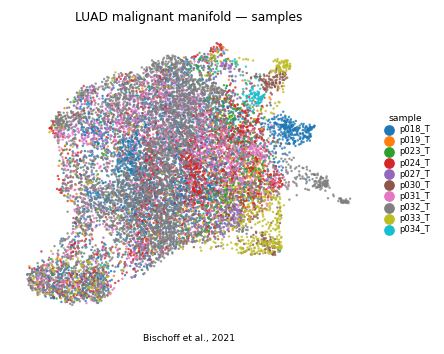

In [12]:
# samples.pdf — malignant manifold coloured by sample (Gate-1 batch-integration evidence).
# The manifold is a 2-D continuum (UMAP major/minor aspect ~1.3), not a 1-D strip, so it is
# shown in 2-D with equal aspect (no forced horizontal-strip warp, which would distort it).
plot = adata.copy()
fig, ax = plt.subplots(figsize=(4.4,3.4))
sc.pl.umap(plot, color='sample', size=10, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_aspect('equal')
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_title('LUAD malignant manifold — samples', size=8)
ax.text(.5, -.08, 'Bischoff et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', adata.shape[0])